# Simulating Human Sleep-Stage Transitions and Nighttime Sleep Fragmentatio

This notebook develops a four-state, 30-second sleep-stage model from manually scored Sleep-EDF Expanded hypnograms. This milestone downloads a fixed pilot subset, prepares reproducible training and held-out data, and checks the transition counts.

## 1. Problem and question

How does increasing the probability of nighttime awakenings affect expected Deep Sleep and REM duration? The planned study will compare an empirical baseline with hypothetical changes in sleep-to-Wake transition probabilities, measuring stage minutes and fragmentation across replicated nights.

## 2. Model, assumptions and equations

Let $X_t$ be the stage in epoch $t$, where each epoch is 30 seconds and the possible states are Wake, Light, Deep and REM. The first-order, time-homogeneous DTMC assumes

$$P_{ij}=\Pr(X_{t+1}=j\mid X_t=i),\qquad \sum_j P_{ij}=1,\qquad \pi_{t+1}=\pi_t P.$$

Here $\pi_t$ is the row vector of state probabilities. Fit each dimensionless transition probability from training counts $C_{ij}$ as $\widehat P_{ij}=C_{ij}/\sum_k C_{ik}$ for rows with observed departures (including self-transitions). Estimate the initial distribution from the observed stages at the starts of training windows. A future simulator will sample from each row's cumulative probabilities using uniform random variates.

For a sleep-state row, if the baseline Wake probability is $q_i=P_{iW}<1$ and the scenario uses $q'_i$, set $P'_{iW}=q'_i$ and $P'_{ij}=P_{ij}(1-q'_i)/(1-q_i)$ for $j\ne W$. The Wake row stays fixed. A stage's total duration in minutes is its epoch count multiplied by $0.5$. An awakening is a sleep-to-Wake transition after sleep onset. The planned experiment uses independent night replications for means and 95% Monte Carlo confidence intervals.

The model pools training participants and assumes the same transition law throughout the analysis window. A homogeneous DTMC implies geometric stage run lengths. The grouped labels are derived from the historical Rechtschaffen–Kales scores. The scenarios are hypothetical model perturbations.

**Concepts applied** — DTMC state evolution, empirical input modelling and discrete inverse-transform sampling, and Monte Carlo estimation with the law of large numbers.

## 3. Implementation

In Colab, choose **Runtime → Run all**. The first code cell installs the EDF+ reader. The notebook downloads only the annotation files from the versioned PhysioNet source.

The fixed pilot manifest includes both listed nights for the first 12 Sleep Cassette participant IDs. A seeded participant split reserves three participants for later validation. This convenience subset keeps development repeatable and manageable. Its representativeness is unknown.

The provisional night window extends up to 30 minutes before the first and after the last scored non-Wake epoch, clipped to the annotated span. The padding follows the approach described in the MNE-Python sleep tutorial [3]. The same rule applies to every record. Original epoch indices remain relative to the recording. Movement, unscored intervals and uncovered epochs remain explicitly invalid. Only adjacent valid epochs within one recording contribute to transition counts.

In [ ]:
%pip install --quiet mne==1.10.2

In [ ]:
from hashlib import sha256
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.error import URLError
from urllib.request import urlopen

import mne
import numpy as np
import pandas as pd
from IPython.display import display

SOURCE = "https://physionet.org/files/sleep-edfx/1.0.0/sleep-cassette/"
MIRROR = "https://physionet-open.s3.amazonaws.com/sleep-edfx/1.0.0/sleep-cassette/"
RECORDS = """
SC4001EC SC4002EC SC4011EH SC4012EC SC4021EH SC4022EJ
SC4031EC SC4032EP SC4041EC SC4042EC SC4051EC SC4052EC
SC4061EC SC4062EC SC4071EC SC4072EH SC4081EC SC4082EP
SC4091EC SC4092EC SC4101EC SC4102EC SC4111EC SC4112EC
""".split()
STATES = ("Wake", "Light", "Deep", "REM")
STAGE_MAP = {
    "Sleep stage W": "Wake",
    "Sleep stage 1": "Light",
    "Sleep stage 2": "Light",
    "Sleep stage 3": "Deep",
    "Sleep stage 4": "Deep",
    "Sleep stage R": "REM",
    "Movement time": None,
    "Sleep stage ?": None,
}
EPOCH_SECONDS = 30
PADDING_EPOCHS = 30 * 60 // EPOCH_SECONDS
SPLIT_SEED = 4042

participants = sorted({record[:5] for record in RECORDS})
held_out = set(np.random.default_rng(SPLIT_SEED).choice(participants, size=3, replace=False))

In [ ]:
def expand_night(annotations):
    """Expand scored spans onto the recording's epoch grid and crop the window."""
    raw_labels = {}
    for onset, duration, label in zip(
        annotations.onset, annotations.duration, annotations.description, strict=True
    ):
        if label not in STAGE_MAP:
            raise ValueError(f"Unexpected Sleep-EDF annotation: {label!r}")
        start = round(onset / EPOCH_SECONDS)
        length = round(duration / EPOCH_SECONDS)
        if (
            start < 0
            or length <= 0
            or not np.isclose(onset, start * EPOCH_SECONDS, rtol=0, atol=1e-6)
            or not np.isclose(duration, length * EPOCH_SECONDS, rtol=0, atol=1e-6)
        ):
            raise ValueError(f"Invalid annotation timing: {onset=}, {duration=}, {label=}")
        for epoch in range(start, start + length):
            if epoch in raw_labels:
                raise ValueError(f"Overlapping annotations at epoch {epoch}")
            raw_labels[epoch] = label

    sleep = [
        epoch for epoch, label in raw_labels.items()
        if STAGE_MAP[label] in ("Light", "Deep", "REM")
    ]
    if not sleep:
        raise ValueError("No scored sleep in recording")
    first = max(min(raw_labels), min(sleep) - PADDING_EPOCHS)
    last = min(max(raw_labels), max(sleep) + PADDING_EPOCHS)
    night = pd.DataFrame({"epoch": range(first, last + 1)})
    night["label"] = night["epoch"].map(raw_labels).fillna("Uncovered")
    night["stage"] = night["label"].map(STAGE_MAP)
    return night


def count_transitions(night):
    """Count adjacent pairs with two valid stages in one recording."""
    following = night["stage"].shift(-1)
    adjacent = night["epoch"].shift(-1).sub(night["epoch"]).eq(1)
    counts = pd.crosstab(night.loc[adjacent, "stage"], following.loc[adjacent])
    return counts.reindex(index=STATES, columns=STATES, fill_value=0).astype("int64")


def fetch_annotation(filename):
    errors = []
    for base_url in (SOURCE, MIRROR):
        url = base_url + filename
        try:
            with urlopen(url, timeout=15) as response:
                return response.read(), response.geturl()
        except (URLError, TimeoutError) as exc:
            errors.append(f"{url}: {exc}")
    raise RuntimeError("Could not download annotation. " + " | ".join(errors))


nights, counts_by_record, audit_rows = {}, {}, []
with TemporaryDirectory(prefix="sleep-edf-") as temp:
    for record in RECORDS:
        participant = record[:5]
        split = "held-out" if participant in held_out else "training"
        filename = f"{record}-Hypnogram.edf"
        contents, url = fetch_annotation(filename)
        try:
            path = Path(temp) / filename
            path.write_bytes(contents)
            night = expand_night(mne.read_annotations(path))
        except (OSError, ValueError, RuntimeError) as exc:
            raise RuntimeError(f"Could not process {url}: {exc}") from exc

        counts = count_transitions(night)
        nights[record] = night
        counts_by_record[record] = counts
        audit_rows.append({
            "record": filename,
            "participant": participant,
            "split": split,
            "source_url": url,
            "sha256": sha256(contents).hexdigest(),
            "first_epoch": night["epoch"].iloc[0],
            "last_epoch": night["epoch"].iloc[-1],
            "window_epochs": len(night),
            "valid_epochs": night["stage"].notna().sum(),
            **{state: night["stage"].eq(state).sum() for state in STATES},
            "movement": night["label"].eq("Movement time").sum(),
            "unscored": night["label"].eq("Sleep stage ?").sum(),
            "uncovered": night["label"].eq("Uncovered").sum(),
            "valid_pairs": counts.to_numpy().sum(),
        })

audit = pd.DataFrame(audit_rows)
split_counts = {
    split: sum(counts_by_record[record] for record in RECORDS
               if (record[:5] in held_out) == (split == "held-out"))
    for split in ("training", "held-out")
}

## 4. Verification

Check that the split is disjoint, all window epochs are accounted for, and the count of valid pairs equals the number of valid epochs minus the number of contiguous valid runs, calculated separately for each recording.

In [ ]:
assert STAGE_MAP["Sleep stage W"] == "Wake"
assert STAGE_MAP["Sleep stage 1"] == "Light"
assert STAGE_MAP["Sleep stage 2"] == "Light"
assert STAGE_MAP["Sleep stage 3"] == "Deep"
assert STAGE_MAP["Sleep stage 4"] == "Deep"
assert STAGE_MAP["Sleep stage R"] == "REM"
assert STAGE_MAP["Movement time"] is None
assert STAGE_MAP["Sleep stage ?"] is None
print("Sleep stage mapping checks passed.")

# Valid pairs on either side of a missing epoch should still count.
night_with_gap = pd.DataFrame({
    "epoch": range(5),
    "stage": ["Wake", "Light", None, "Deep", "REM"],
})
gap_counts = count_transitions(night_with_gap)
assert gap_counts.loc["Wake", "Light"] == 1
assert gap_counts.loc["Deep", "REM"] == 1
assert gap_counts.loc["Light", "Deep"] == 0
assert gap_counts.to_numpy().sum() == 2
print("Missing-stage transition check passed.")

night_with_skipped_epoch = pd.DataFrame({
    "epoch": [0, 1, 3, 4],
    "stage": ["Wake", "Light", "Deep", "REM"],
})
skipped_epoch_counts = count_transitions(night_with_skipped_epoch)
assert skipped_epoch_counts.loc["Wake", "Light"] == 1
assert skipped_epoch_counts.loc["Deep", "REM"] == 1
assert skipped_epoch_counts.loc["Light", "Deep"] == 0
assert skipped_epoch_counts.to_numpy().sum() == 2
print("Non-consecutive epoch transition check passed.")

assert len(audit) == len(RECORDS) == len(set(RECORDS))
assert set(audit["split"]) == {"training", "held-out"}
training_participants = set(audit.loc[audit["split"].eq("training"), "participant"])
held_out_participants = set(audit.loc[audit["split"].eq("held-out"), "participant"])
assert training_participants.isdisjoint(held_out_participants), "Training and held-out participants overlap"
assert audit.groupby("participant")["split"].nunique().eq(1).all()
assert audit.loc[audit["split"].eq("held-out"), "participant"].nunique() == len(held_out)
repeated_held_out = set(np.random.default_rng(SPLIT_SEED).choice(
    participants, size=len(held_out), replace=False
))
assert repeated_held_out == held_out_participants, "Held-out split did not repeat with the same seed"
assert set(participants) - repeated_held_out == training_participants, "Training split did not repeat with the same seed"
print("Participant split reproducibility check passed.")
assert audit[list(STATES)].sum(axis=1).eq(audit["valid_epochs"]).all()
assert audit[["valid_epochs", "movement", "unscored", "uncovered"]].sum(axis=1).eq(
    audit["window_epochs"]
).all()
for record, night in nights.items():
    assert night["epoch"].diff().iloc[1:].eq(1).all()
    valid = night["stage"].notna()
    run_starts = valid & ~valid.shift(fill_value=False)
    assert counts_by_record[record].to_numpy().sum() == valid.sum() - run_starts.sum()
for split, counts in split_counts.items():
    assert counts.to_numpy().sum() == audit.loc[audit["split"].eq(split), "valid_pairs"].sum()
training_row_totals = split_counts["training"].sum(axis=1)
empty_stages = training_row_totals.index[training_row_totals.le(0)].tolist()
assert not empty_stages, f"No outgoing training transitions for: {', '.join(empty_stages)}"
print("Preprocessing checks passed.")

Preprocessing checks passed.


## 5. Experiments and results

The tables audit the preprocessing inputs and transition counts. Rows in the count matrices are source stages and columns are destination stages. Held-out counts are kept separate from training. The planned scenario replications and confidence intervals follow in a later milestone.

In [ ]:
print(f"Source: {SOURCE}")
print(f"Participant split seed: {SPLIT_SEED}")
display(audit)
display(audit.groupby("split").agg(
    participants=("participant", "nunique"),
    recordings=("record", "size"),
    window_epochs=("window_epochs", "sum"),
    valid_epochs=("valid_epochs", "sum"),
    movement=("movement", "sum"),
    unscored=("unscored", "sum"),
    uncovered=("uncovered", "sum"),
    valid_pairs=("valid_pairs", "sum"),
))
for split, counts in split_counts.items():
    print(f"{split}: observed transition counts")
    display(counts)

Source: https://physionet.org/files/sleep-edfx/1.0.0/sleep-cassette/
Participant split seed: 4042


,record,participant,split,source_url,sha256,first_epoch,last_epoch,window_epochs,valid_epochs,Wake,Light,Deep,REM,movement,unscored,uncovered,valid_pairs
0,SC4001EC-Hypnogram.edf,SC400,training,https://physionet-open.s3.amazonaws.com/sleep-...,a4cf67694ade1b52a0ddd06d5817fd45d2d3e8bac5302f...,961,1801,841,841,188,308,220,125,0,0,0,840
1,SC4002EC-Hypnogram.edf,SC400,training,https://physionet-open.s3.amazonaws.com/sleep-...,76e8457a67eaaaa62c7f6cc6e098fbe1c0a9c3fa02fa90...,809,1936,1128,1127,183,432,297,215,1,0,0,1125
2,SC4011EH-Hypnogram.edf,SC401,held-out,https://physionet-open.s3.amazonaws.com/sleep-...,5bbf7b4ed8a95c8d20e4347b08c2ded2ee21e2dac4680d...,658,1760,1103,1103,157,671,105,170,0,0,0,1102
3,SC4012EC-Hypnogram.edf,SC401,held-out,https://physionet-open.s3.amazonaws.com/sleep-...,b6323df8b3867a5fdbd80f0cd8233b59659ac496fa48c8...,583,1768,1186,1186,162,752,96,176,0,0,0,1185
4,SC4021EH-Hypnogram.edf,SC402,training,https://physionet-open.s3.amazonaws.com/sleep-...,62b49b26bf08941cb0e974cfeeb0a820bf7dd43fb0c66d...,669,1693,1025,1025,128,639,95,163,0,0,0,1024
5,SC4022EJ-Hypnogram.edf,SC402,training,https://physionet-open.s3.amazonaws.com/sleep-...,5289ca8a9417307cbbf8b2a4e511909ac742c69d45c17a...,697,1706,1010,1009,125,586,119,179,1,0,0,1007
6,SC4031EC-Hypnogram.edf,SC403,training,https://physionet-open.s3.amazonaws.com/sleep-...,7ec3d3c8d8f1a89d48df4cc85be374fbdf70d4b5ec5ec3...,811,1762,952,952,140,546,57,209,0,0,0,951
7,SC4032EP-Hypnogram.edf,SC403,training,https://physionet-open.s3.amazonaws.com/sleep-...,0ef073c5cfba31459732be96cc51e7106d5650c1db1b96...,861,1771,911,911,136,445,131,199,0,0,0,910
8,SC4041EC-Hypnogram.edf,SC404,held-out,https://physionet-open.s3.amazonaws.com/sleep-...,da33d90216e031a6b04c9ebaddcdf7abc223f1e61fd589...,752,1987,1236,1235,200,786,53,196,1,0,0,1233
9,SC4042EC-Hypnogram.edf,SC404,held-out,https://physionet-open.s3.amazonaws.com/sleep-...,28ece9383d5c49f375a34d63c1226cd0eb8c5a4bb9f887...,1014,2217,1204,1200,185,651,94,270,4,0,0,1195


,participants,recordings,window_epochs,valid_epochs,movement,unscored,uncovered,valid_pairs
split,,,,,,,,
held-out,3,6,6917,6912,5,0,0,6901
training,9,18,18083,18053,30,0,0,18006


training: observed transition counts


stage,Wake,Light,Deep,REM
stage,,,,
Wake,2824,189,1,4
Light,147,8762,355,170
Deep,9,342,2007,1
REM,36,136,0,3023


held-out: observed transition counts


stage,Wake,Light,Deep,REM
stage,,,,
Wake,1072,82,0,11
Light,65,3269,145,79
Deep,7,137,834,1
REM,21,69,1,1108


### Training transition counts

These counts come from the saved preprocessing results. Rows show the current stage and columns show the stage in the next 30-second epoch.

| Current stage | Wake | Light | Deep | REM |
| --- | ---: | ---: | ---: | ---: |
| Wake | 2824 | 189 | 1 | 4 |
| Light | 147 | 8762 | 355 | 170 |
| Deep | 9 | 342 | 2007 | 1 |
| REM | 36 | 136 | 0 | 3023 |

The training set contains 18,006 valid pairs of consecutive 30-second epochs from 18 recordings across nine participants. These counts will be used to estimate the model's transition probabilities. The held-out set contains 6,901 valid pairs from six recordings across three different participants and is reserved for validation.

In both tables, the most common pair is Light → Light, meaning two consecutive epochs were both scored as Light sleep.

The audit shows 30 movement epochs in the training set and 5 in the held-out set. Both sets had zero unscored and zero uncovered epochs. These categories have no usable sleep-stage label, so they break the sequence. A valid transition requires two consecutive epochs with valid stage labels.

### Training transition probabilities

Each probability is the count divided by its row total. Rows show the current stage and columns show the next stage. The table rounds probabilities to six decimal places.

In [ ]:
# Divide each count by its current-stage row total.
training_counts = split_counts["training"].loc[list(STATES), list(STATES)]
training_row_totals = training_counts.sum(axis=1)
empty_stages = training_row_totals.index[training_row_totals.le(0)].tolist()
if empty_stages:
    raise ValueError(f"No outgoing training transitions for: {', '.join(empty_stages)}")
training_transition_probabilities = training_counts.div(training_row_totals, axis="index")
probabilities = training_transition_probabilities.to_numpy()
assert ((probabilities >= 0) & (probabilities <= 1)).all(), "Transition probabilities must be between 0 and 1"
assert np.allclose(probabilities.sum(axis=1), 1), "Each transition probability row must sum to 1"
display(training_transition_probabilities.round(6))

,Wake,Light,Deep,REM
stage,,,,
Wake,0.935719,0.062624,0.000331,0.001325
Light,0.015582,0.928768,0.037630,0.018020
Deep,0.003815,0.144977,0.850784,0.000424
REM,0.011268,0.042567,0.000000,0.946166


### Initial sleep-stage probabilities

Each training recording contributes the first 30-second epoch of its preprocessed window. Windows with an unusable first-epoch stage are excluded from the denominator. The window can begin during the Wake padding before sleep onset.

In [ ]:
# Use the first epoch of each preprocessed training window.
training_first_stages = pd.Series(
    {f"{record}-Hypnogram.edf": night["stage"].iloc[0]
     for record, night in nights.items() if record[:5] not in held_out},
    dtype="object",
)
expected_training_records = audit.loc[audit["split"].eq("training"), "record"]
assert (
    len(training_first_stages) == len(expected_training_records)
    and set(training_first_stages.index) == set(expected_training_records)
), "Expected exactly one first epoch from each training recording and none from held-out recordings"
initial_stage_counts = training_first_stages.value_counts().reindex(list(STATES), fill_value=0)
valid_starts = int(initial_stage_counts.sum())
excluded_starts = len(training_first_stages) - valid_starts
if valid_starts == 0:
    raise ValueError("No training windows have a valid first-epoch sleep stage")

initial_stage_probabilities = initial_stage_counts / valid_starts
assert np.isclose(initial_stage_probabilities.sum(), 1), "Initial stage probabilities must sum to 1"
display(pd.DataFrame({
    "Training starts": initial_stage_counts,
    "Initial probability": initial_stage_probabilities.round(6),
}).rename_axis("Sleep stage"))
print(f"Valid training starts: {valid_starts} of {len(training_first_stages)}. Excluded starts: {excluded_starts}.")
print(f"Initial probability sum: {initial_stage_probabilities.sum():.6f}")

,Training starts,Initial probability
Sleep stage,,
Wake,18,1.0
Light,0,0.0
Deep,0,0.0
REM,0,0.0


Valid training starts: 18 of 18. Excluded starts: 0.
Initial probability sum: 1.000000


### Sample the next sleep stage

Draw the next 30-second stage from the current stage's row in the unrounded training matrix. Pass the same NumPy random generator at each step to continue its random sequence.

In [ ]:
def sample_next_stage(current_stage, transition_probabilities, rng):
    """Draw one next stage using the current stage's transition probabilities."""
    probabilities = transition_probabilities.loc[current_stage, list(STATES)].to_numpy()
    return rng.choice(STATES, p=probabilities)

### Check sampled transition frequencies

Draw 20,000 times from the Light row with a separate seeded generator. Each observed proportion should be within one percentage point of the corresponding training probability.

In [ ]:
frequency_rng = np.random.default_rng(4042)
sample_count = 20_000
draws = [
    sample_next_stage("Light", training_transition_probabilities, frequency_rng)
    for _ in range(sample_count)
]
observed_frequencies = pd.Series(draws).value_counts().reindex(list(STATES), fill_value=0) / sample_count
expected_frequencies = training_transition_probabilities.loc["Light", list(STATES)]
max_frequency_error = (observed_frequencies - expected_frequencies).abs().max()
assert max_frequency_error <= 0.01, f"Sampled frequencies differ by up to {max_frequency_error:.2%}"
print(f"Sampling frequency check passed. Largest difference: {max_frequency_error * 100:.2f} percentage points.")

### Simulate one eight-hour night

Sample the first stage from the training window-start distribution. Use each sampled stage to draw the next 30-second epoch with the same random generator.

In [ ]:
def simulate_night(initial_probabilities, transition_probabilities, rng):
    """Return the ordered stages for one eight-hour sleep window."""
    epoch_count = 8 * 60 * 60 // EPOCH_SECONDS
    starting_weights = initial_probabilities.loc[list(STATES)].to_numpy()
    stages = [rng.choice(STATES, p=starting_weights)]
    for _ in range(epoch_count - 1):
        stages.append(sample_next_stage(stages[-1], transition_probabilities, rng))
    return stages

### Simulate one night with NumPy arrays

Align both probability inputs to the same stage order before sampling. Use integer stage indices during the simulation and convert them to labels at the end.

In [ ]:
def simulate_night_numpy(initial_probabilities, transition_probabilities, rng):
    """Return one eight-hour sequence using NumPy stage indices."""
    stage_order = list(STATES)
    stage_labels = np.asarray(stage_order)
    initial_weights = initial_probabilities.loc[stage_order].to_numpy()
    transition_weights = transition_probabilities.loc[stage_order, stage_order].to_numpy()
    epoch_count = 8 * 60 * 60 // EPOCH_SECONDS
    stage_indices = np.empty(epoch_count, dtype=np.intp)
    stage_indices[0] = rng.choice(len(stage_order), p=initial_weights)
    for epoch in range(1, epoch_count):
        current_stage = stage_indices[epoch - 1]
        stage_indices[epoch] = rng.choice(len(stage_order), p=transition_weights[current_stage])
    return stage_labels[stage_indices].tolist()


numpy_test_night = simulate_night_numpy(
    initial_stage_probabilities, training_transition_probabilities, np.random.default_rng(4042)
)
assert len(numpy_test_night) == 960, "An eight-hour night must contain 960 epochs"
assert set(numpy_test_night).issubset(STATES), "All simulated stages must be valid"
print("NumPy night check passed: 960 epochs with valid sleep stages.")

### Simulate a small batch of nights

Assign a child seed to each night before batching. Each child generates 960 uniform draws. The first selects the starting stage, and the rest select transitions using the cumulative probabilities for the current stage.

In [ ]:
def simulate_nights_batched(initial_probabilities, transition_probabilities, child_seeds):
    """Return one row of sleep-stage labels for each preassigned child seed."""
    stage_order = list(STATES)
    stage_labels = np.asarray(stage_order)
    initial_cdf = initial_probabilities.loc[stage_order].to_numpy().cumsum()
    transition_cdf = transition_probabilities.loc[stage_order, stage_order].to_numpy().cumsum(axis=1)
    initial_cdf /= initial_cdf[-1]
    transition_cdf /= transition_cdf[:, -1:]

    epoch_count = 8 * 60 * 60 // EPOCH_SECONDS
    night_count = len(child_seeds)
    night_draws = np.empty((night_count, epoch_count))
    for night_index, child_seed in enumerate(child_seeds):
        night_draws[night_index] = np.random.default_rng(child_seed).random(epoch_count)

    stage_indices = np.empty((night_count, epoch_count), dtype=np.intp)
    stage_indices[:, 0] = np.searchsorted(initial_cdf, night_draws[:, 0], side="right")
    for epoch in range(1, epoch_count):
        current_rows = transition_cdf[stage_indices[:, epoch - 1]]
        draws = night_draws[:, epoch]
        stage_indices[:, epoch] = np.sum(draws[:, None] >= current_rows, axis=1)
    return stage_labels[stage_indices]


small_batch_seeds = np.random.SeedSequence(4042).spawn(4)
small_batch_nights = simulate_nights_batched(
    initial_stage_probabilities, training_transition_probabilities, small_batch_seeds
)
assert small_batch_nights.shape == (4, 960), "Expected four nights with 960 epochs each"
assert np.isin(small_batch_nights, STATES).all(), "Every simulated stage must be valid"
print("Batch check passed: four nights of 960 epochs with valid stages.")

In [ ]:
test_night_stages = simulate_night(
    initial_stage_probabilities, training_transition_probabilities, np.random.default_rng(4042)
)
assert len(test_night_stages) == 960, "An eight-hour night must contain 960 epochs"
assert set(test_night_stages).issubset(STATES), "All simulated stages must be valid"
print("Night sequence check passed: 960 epochs with valid sleep stages.")

repeated_night_stages = simulate_night(
    initial_stage_probabilities, training_transition_probabilities, np.random.default_rng(4042)
)
assert test_night_stages == repeated_night_stages, "The same seed must reproduce the entire night"
print("Night reproducibility check passed: all stages match with the same seed.")

stage_epoch_counts = pd.Series(test_night_stages).value_counts().reindex(list(STATES), fill_value=0)
stage_minutes = stage_epoch_counts * EPOCH_SECONDS / 60
total_minutes = stage_minutes.sum()
assert np.isclose(total_minutes, 480), f"Expected 480 minutes, got {total_minutes:g}"
display(stage_minutes.rename("Minutes").to_frame().rename_axis("Sleep stage"))
print(f"Total duration: {total_minutes:g} minutes.")

### Sample hypnogram for one baseline night

This example uses the baseline night from the checks above, generated with seed `4042`. Each horizontal step shows the stage for one 30-second epoch. A vertical step shows a change of stage.

In [ ]:
import matplotlib.pyplot as plt

hypnogram_order = ["Deep", "Light", "REM", "Wake"]
hypnogram_positions = {stage: position for position, stage in enumerate(hypnogram_order)}
hypnogram_levels = [hypnogram_positions[stage] for stage in test_night_stages]
hypnogram_hours = np.arange(len(hypnogram_levels) + 1) * EPOCH_SECONDS / 3600

hypnogram_figure, hypnogram_ax = plt.subplots(figsize=(9.2, 3.4), layout="constrained")
hypnogram_ax.stairs(hypnogram_levels, hypnogram_hours, baseline=None, color="#146C80", linewidth=1.5)
hypnogram_ax.set(xlabel="Time since window start (hours)", ylabel="Sleep stage",
                 xlim=(0, 8), ylim=(-0.4, 3.4), title="Simulated baseline night")
hypnogram_ax.set_xticks([0, 2, 4, 6, 8])
hypnogram_ax.set_yticks(range(len(hypnogram_order)), hypnogram_order)
hypnogram_ax.set_axisbelow(True)
hypnogram_ax.grid(color="#E1E7EA", linewidth=0.8)
hypnogram_ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Adjust nighttime awakening probabilities

Apply a multiplier of at least 1 to the Light, Deep, and REM probabilities of moving to Wake. Proportionally rescale the remaining entries in each affected row. A multiplier of 1 gives the baseline, and the reciprocal of the largest sleep-to-Wake probability is the upper limit. The Wake row stays the same.

In [ ]:
def adjust_awakening_probabilities(transition_probabilities, multiplier):
    """Return a copy of the matrix with scaled sleep-to-Wake probabilities."""
    if not np.isfinite(multiplier) or multiplier < 1:
        raise ValueError("The awakening multiplier must be finite and at least 1")

    baseline = transition_probabilities.to_numpy()
    if not ((baseline >= 0) & (baseline <= 1)).all() or not np.allclose(baseline.sum(axis=1), 1):
        raise ValueError("The baseline matrix must have probabilities in [0, 1] and row sums of 1")

    sleep_stages = [stage for stage in STATES if stage != "Wake"]
    largest_wake_probability = transition_probabilities.loc[sleep_stages, "Wake"].max()
    if largest_wake_probability > 0:
        max_multiplier = 1.0 / largest_wake_probability
        if multiplier > max_multiplier:
            raise ValueError(f"The awakening multiplier must be between 1 and {max_multiplier:.17g}")

    adjusted = transition_probabilities.copy()
    if multiplier == 1:
        return adjusted

    for stage in sleep_stages:
        wake_probability = transition_probabilities.loc[stage, "Wake"]
        # Guard against floating-point overshoot at the validated upper limit.
        new_wake_probability = min(multiplier * wake_probability, 1.0)
        remaining_scale = (1 - new_wake_probability) / (1 - wake_probability)
        adjusted.loc[stage, "Wake"] = new_wake_probability
        adjusted.loc[stage, sleep_stages] = transition_probabilities.loc[stage, sleep_stages] * remaining_scale

    probabilities = adjusted.to_numpy()
    if not ((probabilities >= 0) & (probabilities <= 1)).all() or not np.allclose(probabilities.sum(axis=1), 1):
        raise ValueError("The adjusted matrix must have probabilities in [0, 1] and row sums of 1")
    return adjusted

In [ ]:
baseline_snapshot = training_transition_probabilities.copy()
baseline_adjusted = adjust_awakening_probabilities(training_transition_probabilities, 1)
pd.testing.assert_frame_equal(baseline_adjusted, baseline_snapshot, check_exact=True)
pd.testing.assert_frame_equal(training_transition_probabilities, baseline_snapshot, check_exact=True)
assert baseline_adjusted is not training_transition_probabilities, "Expected a separate matrix copy"
print("Multiplier 1 exactly matches the original matrix, and the input is unchanged.")

doubled_awakening = adjust_awakening_probabilities(training_transition_probabilities, 2)
sleep_stages = [stage for stage in STATES if stage != "Wake"]
np.testing.assert_allclose(
    doubled_awakening.loc[sleep_stages, "Wake"],
    2 * baseline_snapshot.loc[sleep_stages, "Wake"],
)
pd.testing.assert_series_equal(doubled_awakening.loc["Wake"], baseline_snapshot.loc["Wake"], check_exact=True)
np.testing.assert_allclose(doubled_awakening.sum(axis=1), 1.0)
print("Multiplier 2 doubles sleep-to-Wake probabilities, preserves the Wake row, and keeps row sums at 1.")

max_multiplier = 1 / baseline_snapshot.loc[sleep_stages, "Wake"].max()
invalid_multipliers = [
    (0.5, "at least 1"),
    (-1, "at least 1"),
    (np.nextafter(max_multiplier, np.inf), "between 1 and"),
    (np.nan, "multiplier must be finite"),
    (np.inf, "multiplier must be finite"),
    (-np.inf, "multiplier must be finite"),
]
for invalid_multiplier, expected_message in invalid_multipliers:
    try:
        adjust_awakening_probabilities(training_transition_probabilities, invalid_multiplier)
    except ValueError as error:
        assert expected_message in str(error), str(error)
    else:
        raise AssertionError(f"Expected ValueError for multiplier {invalid_multiplier}")
print("Invalid multiplier checks passed for out-of-range and non-finite values.")

### Sleep-to-Wake probabilities with multiplier 2

Each row shows the chance of moving to Wake in the next 30-second epoch. The change is the adjusted probability minus the original, in percentage points, calculated before rounding.

In [ ]:
original_wake = training_transition_probabilities.loc[sleep_stages, "Wake"]
doubled_wake = doubled_awakening.loc[sleep_stages, "Wake"]
awakening_comparison = pd.DataFrame({
    "Original (%)": 100 * original_wake,
    "Multiplier 2 (%)": 100 * doubled_wake,
    "Change (percentage points)": 100 * (doubled_wake - original_wake),
}).rename_axis("Current sleep stage")
display(awakening_comparison.round(2))

### Simulate a small batch of matched pairs

Pass the same initial probabilities and ordered child seeds to both scenarios. The same row in each returned array belongs to the same pair.

In [ ]:
def simulate_pairs_batched(initial_probabilities, baseline_matrix, adjusted_matrix, child_seeds):
    """Return baseline and adjusted night arrays in matching pair order."""
    baseline_nights = simulate_nights_batched(initial_probabilities, baseline_matrix, child_seeds)
    adjusted_nights = simulate_nights_batched(initial_probabilities, adjusted_matrix, child_seeds)
    return baseline_nights, adjusted_nights


small_batch_baseline, small_batch_doubled = simulate_pairs_batched(
    initial_stage_probabilities, training_transition_probabilities, doubled_awakening, small_batch_seeds
)
assert small_batch_baseline.shape == small_batch_doubled.shape == (4, 960)

first_baseline, second_baseline = simulate_pairs_batched(
    initial_stage_probabilities, training_transition_probabilities, training_transition_probabilities, small_batch_seeds
)
np.testing.assert_array_equal(first_baseline, second_baseline)
print("Four-pair batch check passed. Identical matrices produced identical sequences.")

### Run 100 paired simulated nights

Each pair uses the same training initial distribution and eight-hour window. A master seed produces one child seed per pair. Two separate generators start from that child seed, one for the baseline matrix and one for the multiplier-2 matrix.

In [ ]:
def simulate_paired_nights(initial_probabilities, baseline_matrix, adjusted_matrix, pair_count, master_seed):
    """Return the baseline and adjusted night sequences in matching pair order."""
    baseline_nights = []
    adjusted_nights = []
    for child_seed in np.random.SeedSequence(master_seed).spawn(pair_count):
        baseline_rng = np.random.default_rng(child_seed)
        adjusted_rng = np.random.default_rng(child_seed)
        baseline_nights.append(simulate_night(initial_probabilities, baseline_matrix, baseline_rng))
        adjusted_nights.append(simulate_night(initial_probabilities, adjusted_matrix, adjusted_rng))
    return baseline_nights, adjusted_nights


pilot_pair_count = 100
pilot_master_seed = 4042
pilot_args = (
    initial_stage_probabilities, training_transition_probabilities, doubled_awakening,
    pilot_pair_count, pilot_master_seed,
)
baseline_pilot_nights, doubled_pilot_nights = simulate_paired_nights(*pilot_args)

for scenario, pilot_nights in (("Baseline", baseline_pilot_nights), ("Multiplier 2", doubled_pilot_nights)):
    assert len(pilot_nights) == pilot_pair_count, f"{scenario} must produce 100 nights"
    assert all(len(night) == 960 and set(night).issubset(STATES) for night in pilot_nights), (
        f"{scenario} contains a night with an incorrect length or invalid stage"
    )

assert simulate_paired_nights(*pilot_args) == (baseline_pilot_nights, doubled_pilot_nights), (
    "The same master seed must reproduce both scenarios"
)
print("Baseline and multiplier 2 each produced 100 valid nights of 960 epochs.")
print("Paired simulation check passed: the same master seed reproduced every stage in both scenarios.")

### Mean Deep Sleep duration in the pilot

Count the Deep epochs in each simulated night and convert them to minutes. Average the 100 night-level durations in each scenario.

In [ ]:
pilot_scenarios = {"Baseline": baseline_pilot_nights, "Multiplier 2": doubled_pilot_nights}
deep_minutes_by_night = pd.DataFrame({
    scenario: [night.count("Deep") * EPOCH_SECONDS / 60 for night in nights]
    for scenario, nights in pilot_scenarios.items()
})
deep_mean_minutes = deep_minutes_by_night.mean()

for scenario, nights in pilot_scenarios.items():
    total_deep_epochs = sum(stage == "Deep" for night in nights for stage in night)
    mean_from_total = total_deep_epochs * EPOCH_SECONDS / (60 * pilot_pair_count)
    assert np.isclose(deep_mean_minutes[scenario], mean_from_total), f"{scenario} mean does not match the epoch total"

display(deep_mean_minutes.round(2).rename("Mean Deep Sleep (min)").to_frame().rename_axis("Scenario"))

### Mean REM duration in the pilot

Count the REM epochs in each of the same simulated nights, convert them to minutes, and average the 100 night-level durations in each scenario.

In [ ]:
rem_minutes_by_night = pd.DataFrame({
    scenario: [night.count("REM") * EPOCH_SECONDS / 60 for night in nights]
    for scenario, nights in pilot_scenarios.items()
})
rem_mean_minutes = rem_minutes_by_night.mean()

for scenario, nights in pilot_scenarios.items():
    total_rem_epochs = sum(stage == "REM" for night in nights for stage in night)
    mean_from_total = total_rem_epochs * EPOCH_SECONDS / (60 * pilot_pair_count)
    assert np.isclose(rem_mean_minutes[scenario], mean_from_total), f"{scenario} REM mean does not match the epoch total"

display(rem_mean_minutes.round(2).rename("Mean REM (min)").to_frame().rename_axis("Scenario"))

### Paired difference in Deep Sleep duration

For each pair, subtract the baseline Deep Sleep minutes from the multiplier-2 minutes. A negative difference means less Deep Sleep under multiplier 2.

In [ ]:
deep_paired_differences = deep_minutes_by_night["Multiplier 2"] - deep_minutes_by_night["Baseline"]
assert len(deep_paired_differences) == pilot_pair_count, "Expected one Deep Sleep difference per pair"
mean_deep_paired_difference = deep_paired_differences.mean()
deep_difference_of_means = deep_mean_minutes["Multiplier 2"] - deep_mean_minutes["Baseline"]
assert np.isclose(mean_deep_paired_difference, deep_difference_of_means), (
    "Mean paired Deep Sleep difference must match the difference between scenario means"
)
print(f"Mean paired Deep Sleep difference: {mean_deep_paired_difference:.3f} minutes.")
print(f"Difference between scenario means: {deep_difference_of_means:.3f} minutes.")

### Paired difference in REM duration

For each pair, subtract the baseline REM minutes from the multiplier-2 minutes. A negative difference means less REM under multiplier 2.

In [ ]:
rem_paired_differences = rem_minutes_by_night["Multiplier 2"] - rem_minutes_by_night["Baseline"]
assert len(rem_paired_differences) == pilot_pair_count, "Expected one REM difference per pair"
mean_rem_paired_difference = rem_paired_differences.mean()
rem_difference_of_means = rem_mean_minutes["Multiplier 2"] - rem_mean_minutes["Baseline"]
assert np.isclose(mean_rem_paired_difference, rem_difference_of_means), (
    "Mean paired REM difference must match the difference between scenario means"
)
print(f"Mean paired REM difference: {mean_rem_paired_difference:.3f} minutes.")
print(f"Difference between scenario means: {rem_difference_of_means:.3f} minutes.")

### 95% confidence interval for the mean paired Deep Sleep difference

Use the sample standard deviation of the paired differences to estimate the standard error. With 100 pairs, the two-sided t interval uses 99 degrees of freedom.

In [ ]:
from scipy.stats import t, ttest_1samp

deep_pair_count = len(deep_paired_differences)
deep_sample_sd = deep_paired_differences.std(ddof=1)
deep_standard_error = deep_sample_sd / np.sqrt(deep_pair_count)
deep_t_critical = t.ppf(0.975, df=deep_pair_count - 1)
deep_margin = deep_t_critical * deep_standard_error
deep_ci_lower = mean_deep_paired_difference - deep_margin
deep_ci_upper = mean_deep_paired_difference + deep_margin

deep_reference_ci = ttest_1samp(deep_paired_differences, popmean=0).confidence_interval(confidence_level=0.95)
np.testing.assert_allclose([deep_ci_lower, deep_ci_upper], [deep_reference_ci.low, deep_reference_ci.high])
print(f"Deep Sleep 95% confidence interval: [{deep_ci_lower:.3f}, {deep_ci_upper:.3f}] minutes.")
print("Both limits match the one-sample t-test interval on the paired differences.")

### 95% confidence interval for the mean paired REM difference

Use the sample standard deviation of the 100 REM paired differences and a two-sided t critical value with 99 degrees of freedom.

In [ ]:
rem_pair_count = len(rem_paired_differences)
rem_sample_sd = rem_paired_differences.std(ddof=1)
rem_standard_error = rem_sample_sd / np.sqrt(rem_pair_count)
rem_t_critical = t.ppf(0.975, df=rem_pair_count - 1)
rem_margin = rem_t_critical * rem_standard_error
rem_ci_lower = mean_rem_paired_difference - rem_margin
rem_ci_upper = mean_rem_paired_difference + rem_margin

rem_reference_ci = ttest_1samp(rem_paired_differences, popmean=0).confidence_interval(confidence_level=0.95)
np.testing.assert_allclose([rem_ci_lower, rem_ci_upper], [rem_reference_ci.low, rem_reference_ci.high])
print(f"REM 95% confidence interval: [{rem_ci_lower:.3f}, {rem_ci_upper:.3f}] minutes.")
print("Both limits match the one-sample t-test interval on the paired differences.")

### Inspect unusual Deep Sleep differences

Flag paired differences more than 1.5 interquartile ranges below Q1 or above Q3. Pair numbers start at 1 and follow the simulation order. The flags are for inspection.

In [ ]:
deep_q1, deep_q3 = deep_paired_differences.quantile([0.25, 0.75]).to_numpy()
deep_iqr = deep_q3 - deep_q1
deep_iqr_lower = deep_q1 - 1.5 * deep_iqr
deep_iqr_upper = deep_q3 + 1.5 * deep_iqr
deep_flagged_positions = np.flatnonzero(
    (deep_paired_differences < deep_iqr_lower) | (deep_paired_differences > deep_iqr_upper)
)

display(pd.DataFrame([{"Q1 (min)": deep_q1, "Q3 (min)": deep_q3, "IQR (min)": deep_iqr,
                       "Lower limit (min)": deep_iqr_lower, "Upper limit (min)": deep_iqr_upper,
                       "Flagged pairs": len(deep_flagged_positions)}]).round(4))

if deep_flagged_positions.size:
    deep_flagged_pairs = deep_minutes_by_night.iloc[deep_flagged_positions].copy()
    deep_flagged_pairs.columns = ["Baseline (min)", "Multiplier 2 (min)"]
    deep_flagged_pairs["Difference (min)"] = deep_paired_differences.iloc[deep_flagged_positions].to_numpy()
    deep_flagged_pairs.index = pd.Index(deep_flagged_positions + 1, name="Pair number")
    display(deep_flagged_pairs)

### Inspect unusual REM differences

Apply the same 1.5 × IQR rule to the REM differences. Pair numbers start at 1 and follow the simulation order.

In [ ]:
rem_q1, rem_q3 = rem_paired_differences.quantile([0.25, 0.75]).to_numpy()
rem_iqr = rem_q3 - rem_q1
rem_iqr_lower = rem_q1 - 1.5 * rem_iqr
rem_iqr_upper = rem_q3 + 1.5 * rem_iqr
rem_flagged_positions = np.flatnonzero(
    (rem_paired_differences < rem_iqr_lower) | (rem_paired_differences > rem_iqr_upper)
)

display(pd.DataFrame([{
    "Q1 (min)": rem_q1,
    "Q3 (min)": rem_q3,
    "IQR (min)": rem_iqr,
    "Lower limit (min)": rem_iqr_lower,
    "Upper limit (min)": rem_iqr_upper,
    "Flagged pairs": len(rem_flagged_positions),
}]).round(4))

if rem_flagged_positions.size:
    rem_flagged_pairs = rem_minutes_by_night.iloc[rem_flagged_positions].copy()
    rem_flagged_pairs.columns = ["Baseline (min)", "Multiplier 2 (min)"]
    rem_flagged_pairs["Difference (min)"] = rem_paired_differences.iloc[rem_flagged_positions].to_numpy()
    rem_flagged_pairs.index = pd.Index(rem_flagged_positions + 1, name="Pair number")
    display(rem_flagged_pairs)

### Count awakenings in a sleep sequence

Count a transition into Wake only when the preceding epoch is Light, Deep, or REM. An initial Wake epoch and consecutive Wake epochs contribute zero.

In [ ]:
def count_awakenings(stages):
    """Count transitions from a sleep stage into Wake."""
    stages = np.asarray(stages)
    previous_is_sleep = np.isin(stages[:-1], ("Light", "Deep", "REM"))
    next_is_wake = stages[1:] == "Wake"
    return np.count_nonzero(previous_is_sleep & next_is_wake)


awakening_example = ["Wake", "Light", "Wake", "Wake", "REM", "Wake"]
assert count_awakenings(awakening_example) == 2
assert count_awakenings(["Wake", "Light"]) == 0
print("Awakening checks passed. The example contains two awakenings, and starting in Wake contributes zero.")

### Final Monte Carlo experiment with 10,000 paired nights

The baseline and multiplier-2 scenarios use the same initial distribution and 960 epochs per night. Assign child seeds from master seed 4042 before batching. Store the Deep Sleep and REM durations and awakening counts in pair order. The paired difference is multiplier 2 minus baseline.

In [ ]:
final_pair_count = 10_000
final_batch_size = 500
final_master_seed = 4042
final_stages = ("Deep", "REM")


def run_final_paired_metrics(master_seed):
    child_seeds = np.random.SeedSequence(master_seed).spawn(final_pair_count)
    baseline_minutes = np.empty((final_pair_count, len(final_stages)))
    doubled_minutes = np.empty_like(baseline_minutes)
    baseline_awakenings = np.empty(final_pair_count, dtype=np.int64)
    doubled_awakenings = np.empty_like(baseline_awakenings)
    for start in range(0, final_pair_count, final_batch_size):
        batch_seeds = child_seeds[start:start + final_batch_size]
        stop = start + len(batch_seeds)
        baseline_nights, doubled_nights = simulate_pairs_batched(
            initial_stage_probabilities, training_transition_probabilities, doubled_awakening, batch_seeds
        )
        assert baseline_nights.shape == doubled_nights.shape == (len(batch_seeds), 960)
        for column, stage in enumerate(final_stages):
            baseline_minutes[start:stop, column] = np.count_nonzero(baseline_nights == stage, axis=1) * EPOCH_SECONDS / 60
            doubled_minutes[start:stop, column] = np.count_nonzero(doubled_nights == stage, axis=1) * EPOCH_SECONDS / 60
        baseline_awakenings[start:stop] = np.fromiter(
            (count_awakenings(night) for night in baseline_nights), dtype=np.int64, count=len(batch_seeds)
        )
        doubled_awakenings[start:stop] = np.fromiter(
            (count_awakenings(night) for night in doubled_nights), dtype=np.int64, count=len(batch_seeds)
        )
    return baseline_minutes, doubled_minutes, baseline_awakenings, doubled_awakenings


(final_baseline_minutes, final_doubled_minutes,
 final_baseline_awakenings, final_doubled_awakenings) = run_final_paired_metrics(final_master_seed)
assert len(final_baseline_minutes) == len(final_doubled_minutes) == 10_000
(replay_baseline_minutes, replay_doubled_minutes,
 replay_baseline_awakenings, replay_doubled_awakenings) = run_final_paired_metrics(final_master_seed)
np.testing.assert_array_equal(final_baseline_minutes, replay_baseline_minutes)
np.testing.assert_array_equal(final_doubled_minutes, replay_doubled_minutes)
np.testing.assert_array_equal(final_baseline_awakenings, replay_baseline_awakenings)
np.testing.assert_array_equal(final_doubled_awakenings, replay_doubled_awakenings)

final_paired_differences = final_doubled_minutes - final_baseline_minutes
final_results = pd.DataFrame({
    "Baseline mean (min)": final_baseline_minutes.mean(axis=0),
    "Multiplier 2 mean (min)": final_doubled_minutes.mean(axis=0),
    "Mean paired difference (min)": final_paired_differences.mean(axis=0),
}, index=pd.Index(["Deep Sleep", "REM"], name="Sleep stage"))
np.testing.assert_allclose(
    final_results["Mean paired difference (min)"],
    final_results["Multiplier 2 mean (min)"] - final_results["Baseline mean (min)"],
)
display(final_results.round(3))
final_mean_awakenings = pd.DataFrame(
    {"Mean awakenings per night": [final_baseline_awakenings.mean(), final_doubled_awakenings.mean()]},
    index=pd.Index(["Baseline", "Multiplier 2"], name="Scenario"),
)
display(final_mean_awakenings.round(3))
print("Verified 10,000 nights per scenario and exact reproduction of every stored duration and count with seed 4042.")

,Baseline mean (min),Multiplier 2 mean (min),Mean paired difference (min)
Sleep stage,,,
Deep Sleep,62.234,53.660,-8.574
REM,83.824,62.996,-20.829


,Mean awakenings per night
Scenario,
Baseline,10.147
Multiplier 2,17.498


Verified 10,000 nights per scenario and exact reproduction of every stored duration and count with seed 4042.


### Final 95% confidence interval for the mean paired Deep Sleep difference

Use the sample standard deviation of the 10,000 paired differences and a two-sided t critical value with 9,999 degrees of freedom. The differences are multiplier 2 minus baseline, in minutes.

In [ ]:
final_deep_differences = final_paired_differences[:, final_stages.index("Deep")]
final_deep_pair_count = len(final_deep_differences)
final_deep_mean = final_deep_differences.mean()
final_deep_sample_sd = final_deep_differences.std(ddof=1)
final_deep_standard_error = final_deep_sample_sd / np.sqrt(final_deep_pair_count)
final_deep_t_critical = t.ppf(0.975, df=final_deep_pair_count - 1)
final_deep_margin = final_deep_t_critical * final_deep_standard_error
final_deep_ci_lower = final_deep_mean - final_deep_margin
final_deep_ci_upper = final_deep_mean + final_deep_margin

final_deep_reference_ci = ttest_1samp(final_deep_differences, popmean=0).confidence_interval(confidence_level=0.95)
np.testing.assert_allclose(
    [final_deep_ci_lower, final_deep_ci_upper],
    [final_deep_reference_ci.low, final_deep_reference_ci.high],
)
print(f"Final Deep Sleep 95% confidence interval: [{final_deep_ci_lower:.3f}, {final_deep_ci_upper:.3f}] minutes.")
print("Both limits match SciPy's one-sample t-test interval on the paired differences.")

Final Deep Sleep 95% confidence interval: [-8.783, -8.365] minutes.
Both limits match SciPy's one-sample t-test interval on the paired differences.


### Final 95% confidence interval for the mean paired REM difference

Use the sample standard deviation of the 10,000 REM paired differences and a two-sided t critical value with 9,999 degrees of freedom. The differences are multiplier 2 minus baseline, in minutes.

In [ ]:
final_rem_differences = final_paired_differences[:, final_stages.index("REM")]
final_rem_pair_count = len(final_rem_differences)
final_rem_mean = final_rem_differences.mean()
final_rem_sample_sd = final_rem_differences.std(ddof=1)
final_rem_standard_error = final_rem_sample_sd / np.sqrt(final_rem_pair_count)
final_rem_t_critical = t.ppf(0.975, df=final_rem_pair_count - 1)
final_rem_margin = final_rem_t_critical * final_rem_standard_error
final_rem_ci_lower = final_rem_mean - final_rem_margin
final_rem_ci_upper = final_rem_mean + final_rem_margin

final_rem_reference_ci = ttest_1samp(final_rem_differences, popmean=0).confidence_interval(confidence_level=0.95)
np.testing.assert_allclose(
    [final_rem_ci_lower, final_rem_ci_upper],
    [final_rem_reference_ci.low, final_rem_reference_ci.high],
)
print(f"Final REM 95% confidence interval: [{final_rem_ci_lower:.3f}, {final_rem_ci_upper:.3f}] minutes.")
print("Both limits match SciPy's one-sample t-test interval on the paired differences.")

Final REM 95% confidence interval: [-21.192, -20.465] minutes.
Both limits match SciPy's one-sample t-test interval on the paired differences.


### Final 95% confidence interval for the mean paired awakening difference

Subtract baseline from multiplier 2 within each pair. Use the sample standard deviation of the 10,000 differences and a two-sided t critical value with 9,999 degrees of freedom.

In [ ]:
final_awakening_differences = final_doubled_awakenings - final_baseline_awakenings
final_awakening_pair_count = len(final_awakening_differences)
final_awakening_mean = final_awakening_differences.mean()
final_awakening_sample_sd = final_awakening_differences.std(ddof=1)
final_awakening_standard_error = final_awakening_sample_sd / np.sqrt(final_awakening_pair_count)
final_awakening_t_critical = t.ppf(0.975, df=final_awakening_pair_count - 1)
final_awakening_margin = final_awakening_t_critical * final_awakening_standard_error
final_awakening_ci_lower = final_awakening_mean - final_awakening_margin
final_awakening_ci_upper = final_awakening_mean + final_awakening_margin

final_awakening_reference_ci = ttest_1samp(
    final_awakening_differences, popmean=0
).confidence_interval(confidence_level=0.95)
np.testing.assert_allclose(
    [final_awakening_ci_lower, final_awakening_ci_upper],
    [final_awakening_reference_ci.low, final_awakening_reference_ci.high],
)
print(f"Mean paired awakening difference: {final_awakening_mean:.4f} awakenings per night.")
print(f"95% confidence interval: [{final_awakening_ci_lower:.4f}, {final_awakening_ci_upper:.4f}] awakenings per night.")
print("Both limits match SciPy's one-sample t-test interval on the paired differences.")

Mean paired awakening difference: 7.3511 awakenings per night.
95% confidence interval: [7.3000, 7.4022] awakenings per night.
Both limits match SciPy's one-sample t-test interval on the paired differences.


### Final Monte Carlo results summary

Results are based on 10,000 matched pairs of eight-hour nights. Paired differences are multiplier 2 minus baseline. Each confidence interval is for the mean paired difference and uses the unit shown for that outcome.

In [ ]:
final_summary = final_results.rename(
    index={"Deep Sleep": "Deep Sleep (min)", "REM": "REM (min)"},
    columns={
        "Baseline mean (min)": "Baseline mean",
        "Multiplier 2 mean (min)": "Multiplier 2 mean",
        "Mean paired difference (min)": "Mean paired difference",
    },
).rename_axis("Outcome")
final_summary.loc["Awakenings per night"] = [
    final_mean_awakenings.loc["Baseline", "Mean awakenings per night"],
    final_mean_awakenings.loc["Multiplier 2", "Mean awakenings per night"],
    final_awakening_mean,
]
final_summary["95% CI for mean difference"] = [
    f"[{final_deep_ci_lower:.3f}, {final_deep_ci_upper:.3f}]",
    f"[{final_rem_ci_lower:.3f}, {final_rem_ci_upper:.3f}]",
    f"[{final_awakening_ci_lower:.3f}, {final_awakening_ci_upper:.3f}]",
]
display(final_summary.round(3))

,Baseline mean,Multiplier 2 mean,Mean paired difference,95% CI for mean difference
Outcome,,,,
Deep Sleep (min),62.234,53.660,-8.574,"[-8.783, -8.365]"
REM (min),83.824,62.996,-20.829,"[-21.192, -20.465]"
Awakenings per night,10.147,17.498,7.351,"[7.300, 7.402]"


### Final Monte Carlo results by scenario

Bars show scenario means across 10,000 matched pairs. The table above gives the confidence intervals for the paired differences.

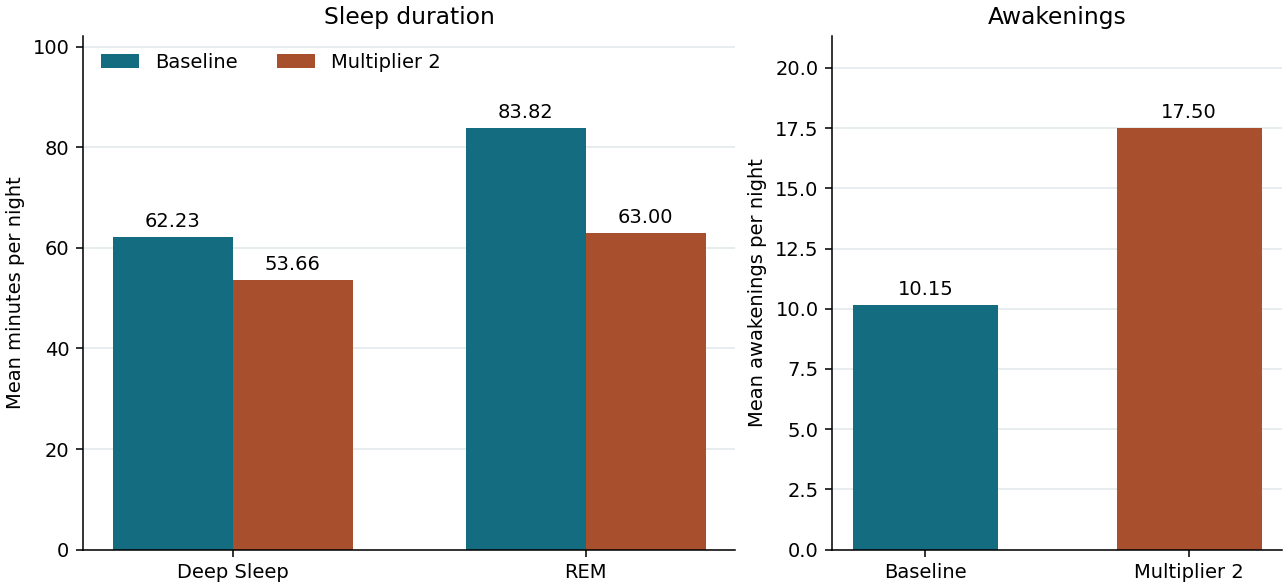

In [ ]:
import matplotlib.pyplot as plt

scenarios = ("Baseline", "Multiplier 2")
colors = ("#146C80", "#A8502D")
duration_means = final_summary.loc[["Deep Sleep (min)", "REM (min)"],
                                   ["Baseline mean", "Multiplier 2 mean"]]
awakening_means = final_mean_awakenings.loc[list(scenarios), "Mean awakenings per night"]

fig, (duration_ax, awakening_ax) = plt.subplots(
    1, 2, figsize=(9.2, 4.2), gridspec_kw={"width_ratios": [1.45, 1]}, layout="constrained"
)
positions = np.arange(len(duration_means))
bar_width = 0.34
for i, (scenario, color) in enumerate(zip(scenarios, colors)):
    bars = duration_ax.bar(positions + (i - 0.5) * bar_width, duration_means.iloc[:, i],
                           width=bar_width, color=color, label=scenario)
    duration_ax.bar_label(bars, fmt="%.2f", padding=3)
duration_ax.set_xticks(positions, ["Deep Sleep", "REM"])
duration_ax.set_title("Sleep duration")
duration_ax.set_ylabel("Mean minutes per night")
duration_ax.set_ylim(0, duration_means.to_numpy().max() * 1.22)
duration_ax.legend(loc="upper left", frameon=False, ncol=2)

awakening_bars = awakening_ax.bar(scenarios, awakening_means, color=colors, width=0.55)
awakening_ax.bar_label(awakening_bars, fmt="%.2f", padding=3)
awakening_ax.set_title("Awakenings")
awakening_ax.set_ylabel("Mean awakenings per night")
awakening_ax.set_ylim(0, awakening_means.max() * 1.22)

for ax in (duration_ax, awakening_ax):
    ax.set_axisbelow(True)
    ax.grid(axis="y", color="#E1E7EA", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

### Held-out transition probabilities

Divide each held-out row by its total transition count. Rows show the current stage and columns show the next stage. A row with zero transitions is unavailable because there are no observed transitions from that stage.

In [ ]:
held_out_counts = split_counts["held-out"].loc[list(STATES), list(STATES)]
held_out_row_totals = held_out_counts.sum(axis=1)
held_out_available_rows = held_out_row_totals.gt(0)
held_out_transition_probabilities = held_out_counts.div(
    held_out_row_totals.where(held_out_available_rows), axis="index"
)
np.testing.assert_allclose(
    held_out_transition_probabilities.loc[held_out_available_rows].sum(axis=1), 1.0
)
display(held_out_row_totals.rename("Held-out transition count").to_frame().rename_axis("Current stage"))
held_out_display = held_out_transition_probabilities.round(6).astype(object)
display(held_out_display.where(held_out_display.notna(), "Unavailable").rename_axis("Current stage"))
print(f"All {held_out_available_rows.sum()} available held-out rows sum to 1 before rounding.")

,Held-out transition count
Current stage,
Wake,1165
Light,3558
Deep,979
REM,1199


,Wake,Light,Deep,REM
Current stage,,,,
Wake,0.920172,0.070386,0.0,0.009442
Light,0.018269,0.918775,0.040753,0.022203
Deep,0.00715,0.139939,0.85189,0.001021
REM,0.017515,0.057548,0.000834,0.924103


All 4 available held-out rows sum to 1 before rounding.


### Held-out minus training transition probabilities

Differences are in percentage points. A positive value means the transition was more common in the held-out recordings. The largest gap is selected before rounding.

In [ ]:
transition_differences_pp = 100 * (held_out_transition_probabilities - training_transition_probabilities)
transition_differences_pp = transition_differences_pp.loc[list(STATES), list(STATES)]
difference_display = transition_differences_pp.apply(
    lambda column: column.map(lambda value: f"{value:.2f}" if pd.notna(value) else "Unavailable")
)
display(difference_display.rename_axis("Current stage"))

absolute_differences = np.abs(transition_differences_pp.to_numpy())
if np.isfinite(absolute_differences).any():
    row, column = np.unravel_index(np.nanargmax(absolute_differences), absolute_differences.shape)
    largest_difference = transition_differences_pp.iloc[row, column]
    print(f"Largest absolute difference: {STATES[row]} to {STATES[column]}, "
          f"{abs(largest_difference):.2f} percentage points (held-out minus training: {largest_difference:+.2f}).")
else:
    print("No held-out rows are available for comparison.")

,Wake,Light,Deep,REM
Current stage,,,,
Wake,-1.55,0.78,-0.03,0.81
Light,0.27,-1.00,0.31,0.42
Deep,0.33,-0.50,0.11,0.06
REM,0.62,1.50,0.08,-2.21


Largest absolute difference: REM to REM, 2.21 percentage points (held-out minus training: -2.21).


The largest difference was REM → REM. The chance of staying in REM for another 30-second epoch was 2.21 percentage points lower in the held-out recordings than in training. Transitions into Wake were more common in the held-out recordings from all three sleep stages: 0.27 percentage points higher from Light, 0.33 from Deep, and 0.62 from REM.

The fitted matrix therefore estimates more persistent REM and lower one-step awakening probabilities than observed in the held-out recordings. This comparison checks individual transitions. How well the model reproduces whole-night stage durations and awakening counts remains a separate question.

## 6. Discussion and limitations

The first/last scored sleep rule is an approximation of the night window. Wake counts and estimated starting stages depend on the selected padding. Missing intervals interrupt transitions, so the matrices describe observed valid neighbours. The pilot is small, and pooled counts give more weight to recordings with more observed transitions. Later validation will compare simulated and held-out stage durations and awakening counts under consistent window and metric definitions.

## 7. References

1. B. Kemp, *Sleep-EDF Database Expanded*, v1.0.0, PhysioNet. [Dataset and annotation documentation](https://physionet.org/content/sleep-edfx/1.0.0/). DOI: 10.13026/C2X676. [ODC Attribution v1.0 licence](https://physionet.org/content/sleep-edfx/view-license/1.0.0/).
2. B. Kemp, A. H. Zwinderman, B. Tuk, H. A. C. Kamphuisen, and J. J. L. Oberyé, “Analysis of a sleep-dependent neuronal feedback loop: the slow-wave microcontinuity of the EEG,” *IEEE Transactions on Biomedical Engineering*, vol. 47, no. 9, pp. 1185–1194, 2000. [Publisher record](https://ieeexplore.ieee.org/document/867928/).
3. MNE-Python contributors, “Sleep stage classification from polysomnography (PSG) data.” [MNE-Python tutorial](https://mne.tools/stable/auto_tutorials/clinical/60_sleep.html#extract-30s-events-from-annotations).